# Part 0 — Cleaning a raw low-cost sensor dataset (Kanpur, Jul–Aug 2026)

The Bihar file used in Parts 1–5 was cleaned upstream. Here we do that cleaning ourselves on a raw file from **76 low-cost PM2.5 sensors in Kanpur** and document every decision.

**Golden rules of this notebook**
1. **Flag, never delete.** Every reading stays in the output file; a `flag` column says whether it is usable.
2. **Never fill gaps.** A missing hour stays missing (`pm25` = NaN, flag `missing` / `outage`).
3. **Every threshold is justified with a plot or a number from the data**, not just asserted.

Steps (PDF section 5): 1 understand the format → 2 reshape to hourly long → 3 detect and flag problems → 4 write `kanpur_hourly_clean.csv` → 5 calibration check between the two device families → 6 before/after summary and daily cycle in IST.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MP1 = Path.cwd()
sys.path.insert(0, str(MP1))
from src import config as C, data as D

RANDOM_STATE = C.RANDOM_STATE
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
C.FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
FAM_COLORS = {"10-digit": "#2a78d6", "8-char": "#eb6834", "12-char hex": "#1baf7a"}   # fixed colour per family

def savefig(fig, name):
    fig.savefig(C.FIG_DIR / name, dpi=130, bbox_inches="tight")

## 1. Understand the format

**What:** the raw file is *wide*: one row per 15-minute UTC time stamp, three columns per sensor (`<id>_latitude`, `<id>_longitude`, `<id>_pm25`).
We answer the PDF's four questions: how many sensors; how often each actually reports; does any sensor move; and how the ID styles differ (resolution and typical level).

In [2]:
raw = pd.read_csv(C.KANPUR_RAW)
raw["timestamp_utc"] = pd.to_datetime(raw["timestamp_utc"], utc=True)
raw = raw.set_index("timestamp_utc")
ids = sorted({c.rsplit("_", 1)[0] for c in raw.columns})
pm = raw[[f"{i}_pm25" for i in ids]].set_axis(ids, axis=1)
lat = raw[[f"{i}_latitude" for i in ids]].set_axis(ids, axis=1)
lon = raw[[f"{i}_longitude" for i in ids]].set_axis(ids, axis=1)

def family(i):
    if len(i) == 10 and i.isdigit(): return "10-digit"
    if len(i) == 8: return "8-char"
    return "12-char hex"
fam = pd.Series({i: family(i) for i in ids}, name="family")

print("time grid:", raw.index.min(), "->", raw.index.max(), "|", len(raw), "rows, step", raw.index.to_series().diff().mode()[0])
print("number of sensors:", len(ids))
display(fam.value_counts().to_frame("n_sensors"))
print("odd IDs:", [i for i in ids if family(i) == "12-char hex"])

time grid: 2026-07-01 00:00:00+00:00 -> 2026-08-31 23:45:00+00:00 | 5952 rows, step 0 days 00:15:00
number of sensors: 76


,n_sensors
family,
10-digit,44
8-char,31
12-char hex,1


odd IDs: ['AC0BFBE34CC7']


### 1a. How often does each sensor actually report?

The grid is 15-minute, but a sensor may not use every slot. We count, per sensor, the share of 15-minute slots with a reading, the share of **hours** with at least one reading, and at which minutes of the hour readings arrive.

family                            10-digit  12-char hex    8-char
readings                   count    44.000        1.000    31.000
                           mean   1127.977     4843.000  1009.290
                           std     182.275          NaN   146.833
                           min     762.000     4843.000   791.000
                           25%     987.000     4843.000   861.500
                           50%    1183.500     4843.000  1014.000
                           75%    1296.750     4843.000  1125.000
                           max    1306.000     4843.000  1232.000
share_of_15min_slots       count    44.000        1.000    31.000
                           mean      0.189        0.814     0.170
                           std       0.030          NaN     0.025
                           min       0.128        0.814     0.133
                           25%       0.166        0.814     0.144
                           50%       0.198        0.814     0.170
                           75%       0.218        0.814     0.190
                           max       0.219        0.814     0.207
share_of_hours             count    44.000        1.000    31.000
                           mean      0.758        0.815     0.678
                           std       0.123          NaN     0.099
                           min       0.512        0.815     0.532
                           25%       0.663        0.815     0.579
                           50%       0.796        0.815     0.681
                           75%       0.871        0.815     0.756
                           max       0.878        0.815     0.828
readings_per_reported_hour count    44.000        1.000    31.000
                           mean      1.000        4.000     1.000
                           std       0.000          NaN     0.000
                           min       1.000        4.000     1.000
                           25%       1.000        4.000     1.000
                           50%       1.000        4.000     1.000
                           75%       1.000        4.000     1.000
                           max       1.000        4.000     1.000

share of readings at each minute of the hour, by family:


timestamp_utc,0,15,30,45
family,,,,
10-digit,1.00,0.00,0.00,0.00
12-char hex,0.25,0.25,0.25,0.25
8-char,1.00,0.00,0.00,0.00


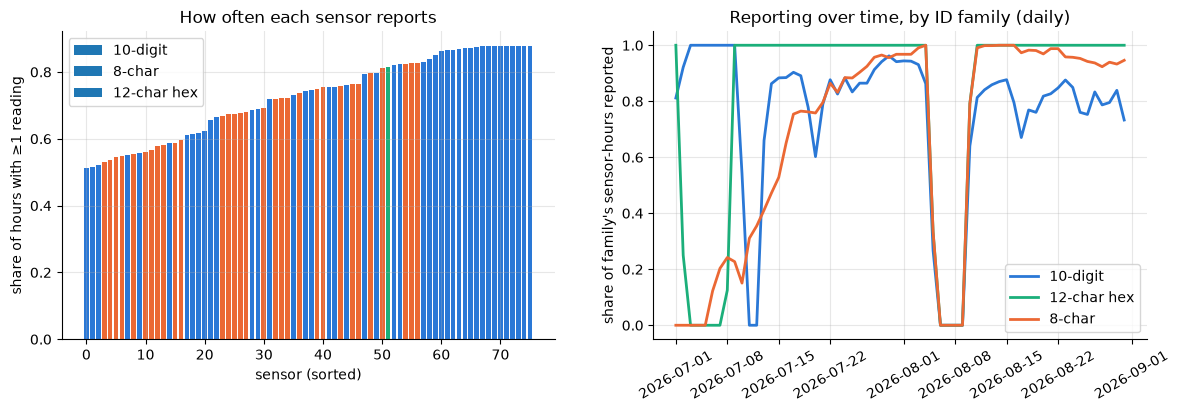

In [3]:
has = pm.notna()
minute = raw.index.minute
report = pd.DataFrame({
    "family": fam,
    "readings": has.sum(),
    "share_of_15min_slots": has.mean().round(3),
    "share_of_hours": has.groupby(raw.index.floor("h")).any().mean().round(3),
    "readings_per_reported_hour": (has.sum() / has.groupby(raw.index.floor("h")).any().sum()).round(2),
})
display(report.groupby("family")[["readings", "share_of_15min_slots", "share_of_hours", "readings_per_reported_hour"]].describe().T.round(3))
print("share of readings at each minute of the hour, by family:")
display(has.groupby(minute).sum().T.groupby(fam).sum().div(has.sum().groupby(fam).sum(), axis=0).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r = report.sort_values("share_of_hours")
axes[0].bar(range(len(r)), r.share_of_hours, color=[FAM_COLORS[f] for f in r.family])
axes[0].set_xlabel("sensor (sorted)"); axes[0].set_ylabel("share of hours with ≥1 reading"); axes[0].set_title("How often each sensor reports")
for f, c in FAM_COLORS.items(): axes[0].bar([], [], color=c, label=f)
axes[0].legend()
daily = has.groupby(raw.index.floor("h")).any().T.groupby(fam).mean().T.resample("D").mean()
for f in daily.columns: axes[1].plot(daily.index, daily[f], color=FAM_COLORS[f], label=f)
axes[1].set_ylabel("share of family's sensor-hours reported"); axes[1].set_title("Reporting over time, by ID family (daily)")
axes[1].legend(); axes[1].tick_params(axis="x", rotation=30)
savefig(fig, "part0_reporting.png"); plt.show()

**What we see.**
* The 15-minute grid is mostly empty: the 10-digit and 8-char sensors report **once per hour, always at minute :00** (1.0 reading per reported hour). Only the hex sensor `AC0BFBE34CC7` uses all four slots (4 readings per hour). So "share of 15-min slots" (≈ 0.17–0.19) understates availability; the meaningful measure is the **share of hours**: median ≈ 0.80 for 10-digit, ≈ 0.68 for 8-char, 0.82 for the hex sensor.
* Reporting changes over time *by family*: the 8-char family comes online gradually during the first half of July (≈ 0 % of hours on 1 Jul, ≈ 65 % by mid-July), the 10-digit family has a multi-day gap around 10–11 July, and **every** sensor stops for several days around 5–10 August (the network outage of step 3d).

### 1b. Does any sensor move?

A sensor "moves" if its latitude or longitude changes over time. We count distinct coordinate values per sensor (ignoring NaN) and the largest change in metres.

In [4]:
n_lat, n_lon = lat.nunique(), lon.nunique()
span_m = pd.concat([(lat.max() - lat.min()) * 110.6e3, (lon.max() - lon.min()) * 100.3e3], axis=1).max(axis=1)
print("sensors with more than one latitude value:", int((n_lat > 1).sum()), "| more than one longitude value:", int((n_lon > 1).sum()))
print("largest coordinate change of any sensor: %.1f m" % span_m.max())
print("coordinates present while pm25 is missing:", int((lat.notna() & pm.isna()).sum().sum()), "cells;",
      "pm25 present without coordinates:", int((lat.isna() & pm.notna()).sum().sum()))
loc = pd.DataFrame({"latitude": lat.median(), "longitude": lon.median(), "family": fam})
display(loc.describe().round(4))

sensors with more than one latitude value: 0 | more than one longitude value: 0
largest coordinate change of any sensor: 0.0 m
coordinates present while pm25 is missing: 366590 cells; pm25 present without coordinates: 0


,latitude,longitude
count,76.0000,76.0000
mean,26.4509,80.2720
std,0.1149,0.0962
min,26.1264,79.9745
25%,26.3708,80.2068
50%,26.4398,80.2634
75%,26.5116,80.3329
max,26.8449,80.4888


**No sensor moves.** Every sensor has a single latitude and a single longitude for the whole two months (largest change 0 m). Coordinates are filled in even when no PM2.5 is reported, so coordinates alone cannot tell us when a sensor is active. The sensors span about 26.13–26.84 °N and 79.97–80.49 °E (Kanpur and surroundings).

### 1c. How do the ID styles differ? (resolution and typical level)

* **Resolution:** do the values come as whole numbers or with decimals?
* **Typical level:** a fair comparison must use the *same hours* (pollution changes over time), so besides the overall median we compare family medians on hours when both families report. We exclude the obvious error code 999 and zeros here (they are studied in step 3).

most frequent raw values: {32.0: 3192, 37.0: 2593, 30.0: 2478, 34.0: 2236, 39.0: 2090, 31.0: 1876, 42.0: 1732, 35.0: 1683}


,n,share_integer,median,mean,p05,p95,typical decimals
family,,,,,,,
10-digit,48700,1.000,37.000,40.149,12.000,73.000,"[81.0, 68.0, 65.0]"
12-char hex,4826,1.000,25.000,24.483,9.000,40.000,"[25.0, 34.0, 29.0]"
8-char,31272,0.001,33.027,37.357,12.092,74.787,"[15.6933, 12.4608, 20.7227]"


hours where both families report: 1167;  median of (10-digit median − 8-char median) = 2.22 µg/m³; ratio of means = 1.033


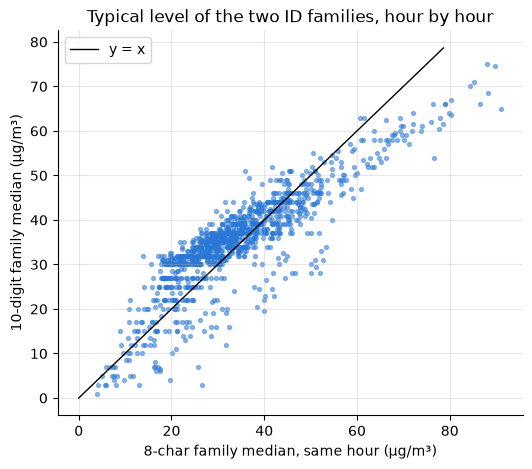

In [5]:
vals = pm.stack().rename("pm25").reset_index().rename(columns={"level_1": "sensor_id"})
vals["family"] = vals["sensor_id"].map(fam)
print("most frequent raw values:", vals.pm25.value_counts().head(8).to_dict())
plaus = vals[(vals.pm25 != 999) & (vals.pm25 > 0)]
res = plaus.groupby("family").pm25.agg(
    n="size", share_integer=lambda v: np.mean(v == np.round(v)), median="median", mean="mean",
    p05=lambda v: v.quantile(.05), p95=lambda v: v.quantile(.95))
res["typical decimals"] = plaus.groupby("family").pm25.agg(lambda v: v.head(3).round(4).tolist())
display(res.round(3))

# same-hour comparison of family medians
hour_med = pm.where((pm != 999) & (pm > 0)).groupby(raw.index.floor("h")).mean().T.groupby(fam).median().T
both = hour_med[["10-digit", "8-char"]].dropna()
print(f"hours where both families report: {len(both)};  median of (10-digit median − 8-char median) = "
      f"{(both['10-digit'] - both['8-char']).median():.2f} µg/m³; ratio of means = {both['10-digit'].mean() / both['8-char'].mean():.3f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(both["8-char"], both["10-digit"], s=8, alpha=0.5, color="#2a78d6")
lim = [0, np.nanpercentile(both.values, 99.5)]
ax.plot(lim, lim, color="black", lw=1, label="y = x")
ax.set_xlabel("8-char family median, same hour (µg/m³)"); ax.set_ylabel("10-digit family median (µg/m³)")
ax.set_title("Typical level of the two ID families, hour by hour"); ax.legend()
savefig(fig, "part0_family_levels.png"); plt.show()

**The ID styles look like different device types.**
* **Resolution:** 10-digit sensors report **whole numbers only** (100 % integers); 8-char sensors report **decimals** (≈ 0.1 % integers, values such as 15.6933 — they look like averages computed on the device); the hex sensor reports integers every 15 minutes.
* **Typical level:** overall medians are 37 (10-digit) vs 33 µg/m³ (8-char), but those medians mix different hours. Compared **hour by hour**, the 10-digit family median is only ≈ 2 µg/m³ higher and the ratio of means is 1.03: the two families measure almost the same typical level. The hex sensor reads lower (median 25 µg/m³).

## 2. Reshape to an hourly long table

**What:** one row per (sensor, hour) with columns `sensor_id, timestamp_utc, latitude, longitude, pm25`. If a sensor reports more often than hourly, we **average the readings within the hour** and label the hour by its **start** (e.g. 10:00–10:59 → 10:00).

**One decision before averaging:** an error code (999) or an out-of-range value averaged with real readings would produce a believable-looking but wrong number. So reading-level problems are detected on the **raw 15-minute readings first** (step 3a), and the hourly mean uses only the *plausible* raw readings of that hour. If *all* readings in an hour are problematic, the hour keeps the mean of those raw values and is flagged — nothing is thrown away.

In [6]:
# long table of every raw reading
long_raw = pm.stack().rename("pm25").reset_index().rename(columns={"level_1": "sensor_id"})
long_raw["hour"] = long_raw["timestamp_utc"].dt.floor("h")
long_raw["minute"] = long_raw["timestamp_utc"].dt.minute
print("raw readings:", len(long_raw))

raw readings: 85762


### 3a (done before averaging). Reading-level checks on raw values

* **Error code:** the value 999 appears as a spike of identical values far above everything else (see the histogram); real low-cost sensors use such sentinel values to signal a fault.
* **Out of range:** values above 500 µg/m³ (excluding 999). Low-cost optical sensors of this type have a nominal range up to about 500 µg/m³ (the Bihar data is capped at exactly 500), and Kanpur monsoon PM2.5 is typically 20–60 µg/m³. We check where they occur.
* **Implausible zero:** PM2.5 is never exactly 0 µg/m³ outdoors in an Indian city; a 0 means "no measurement" or a fault. We check whether zeros come in long runs (fault) or scattered (also implausible).

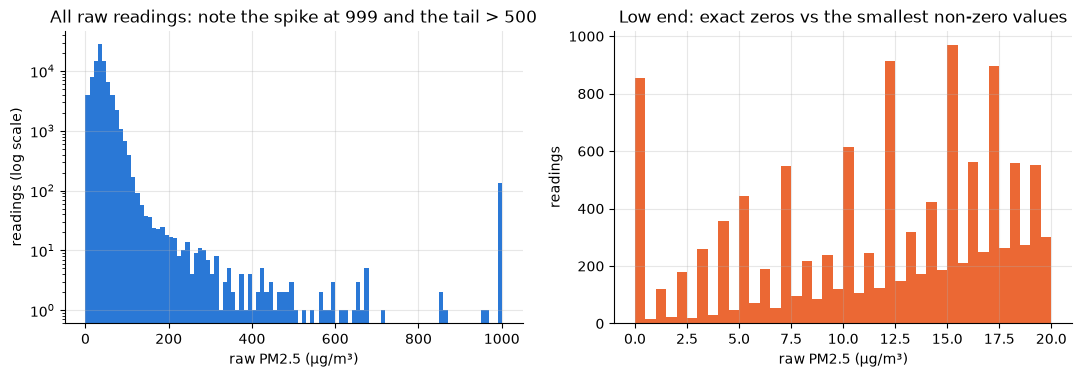

is_error_code   :  136 raw readings in  5 sensors -> {'1204260025': 120, '1203260086': 8, '1203260125': 3, '1203260075': 3, '1203260084': 2}
is_out_of_range :   28 raw readings in 11 sensors -> {'1204260025': 13, '1203260075': 4, '1204260032': 2, '1204260039': 2, '1204260016': 1, '1203260125': 1, '1203260074': 1, '1203260078': 1, '7ZRGMDXU': 1, '1204260027': 1, '1203260145': 1}
is_zero         :  828 raw readings in 21 sensors -> {'1203260082': 414, '1203260068': 350, 'AC0BFBE34CC7': 17, '1204260039': 16, '1204260005': 5, '04TGTKIS': 5, 'TUOBZVJ0': 3, '1203260160': 3, 'I18NGIHK': 2, '01DQW5QE': 2, '1203260159': 1, '1203260123': 1, '1203260086': 1, '1204260004': 1, 'DDJMYBH3': 1, '1204260027': 1, '1204260014': 1, '1203260081': 1, '7ZRGMDXU': 1, 'UI2WKRUR': 1, 'UTCMVKCT': 1}
smallest non-zero value: 0.003; readings equal to 1.0: 111 (spread over 37 sensors, so kept as plausible low readings)


In [7]:
v = long_raw.pm25
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(v, bins=np.arange(0, 1010, 10), color="#2a78d6"); axes[0].set_yscale("log")
axes[0].set_xlabel("raw PM2.5 (µg/m³)"); axes[0].set_ylabel("readings (log scale)"); axes[0].set_title("All raw readings: note the spike at 999 and the tail > 500")
axes[1].hist(v[v < 20], bins=np.arange(0, 20.5, 0.5), color="#eb6834"); axes[1].set_xlabel("raw PM2.5 (µg/m³)")
axes[1].set_ylabel("readings"); axes[1].set_title("Low end: exact zeros vs the smallest non-zero values")
savefig(fig, "part0_raw_histograms.png"); plt.show()

long_raw["is_error_code"] = v == 999
long_raw["is_out_of_range"] = (v > 500) & (v != 999)
long_raw["is_zero"] = v == 0
long_raw["raw_bad"] = long_raw[["is_error_code", "is_out_of_range", "is_zero"]].any(axis=1)

def who(mask):
    s = long_raw.loc[mask, "sensor_id"].value_counts()
    return s.to_dict()
for col in ["is_error_code", "is_out_of_range", "is_zero"]:
    print(f"{col:16s}: {int(long_raw[col].sum()):4d} raw readings in {long_raw.loc[long_raw[col], 'sensor_id'].nunique():2d} sensors -> {who(long_raw[col])}")
print("smallest non-zero value: %.3f; readings equal to 1.0: %d (spread over %d sensors, so kept as plausible low readings)" %
      (v[v > 0].min(), int((v == 1).sum()), long_raw.loc[v == 1, "sensor_id"].nunique()))

**What the reading-level checks catch (raw 15-minute readings):**
* **Error code 999:** 136 readings in 5 sensors, almost all (120) from `1204260025`, which in late August alternates between 999 and impossible values.
* **Out of range (> 500, not 999):** 28 readings in 11 sensors (values 503–968). They are isolated single-hour spikes, or come from the same failing sensor `1204260025`; the network never comes close to such levels in the monsoon (99th percentile of all readings ≈ 108 µg/m³).
* **Implausible zeros:** 828 readings in 21 sensors, dominated by two sensors with **hundreds of consecutive zeros** (`1203260082`: 414, `1203260068`: 350) — clearly dead sensors. The remaining zeros are scattered single readings, still implausible for outdoor PM2.5.
* Values of exactly 1.0 (111 readings) are spread thinly over 37 sensors, as expected for the lowest reading of an integer-resolution sensor on a very clean (rainy) hour, so we keep them.

In [8]:
# hourly aggregation: mean of the plausible raw readings in each (sensor, hour)
g = long_raw.groupby(["sensor_id", "hour"])
hourly = pd.DataFrame({
    "n_raw": g.size(),
    "n_plausible": g["raw_bad"].apply(lambda b: int((~b).sum())),
    "mean_plausible": long_raw[~long_raw.raw_bad].groupby(["sensor_id", "hour"]).pm25.mean(),
    "mean_all": g.pm25.mean(),
    "any_error_code": g.is_error_code.any(), "any_out_of_range": g.is_out_of_range.any(), "any_zero": g.is_zero.any(),
})
hourly["pm25"] = hourly["mean_plausible"].fillna(hourly["mean_all"])          # all-bad hours keep their raw mean
hourly["all_bad"] = hourly["n_plausible"] == 0
hourly = hourly.reset_index().rename(columns={"hour": "timestamp_utc"})
print("sensor-hours with at least one reading:", len(hourly))
print("hours with more than one raw reading:", int((hourly.n_raw > 1).sum()), "— sensors:", hourly.loc[hourly.n_raw > 1, "sensor_id"].unique().tolist())
print("hours mixing plausible and bad readings (bad ones left out of the mean):", int(((hourly.n_plausible > 0) & (hourly.n_plausible < hourly.n_raw)).sum()))

sensor-hours with at least one reading: 82131
hours with more than one raw reading: 1212 — sensors: ['AC0BFBE34CC7']
hours mixing plausible and bad readings (bad ones left out of the mean): 5


### Hour-average vs keeping only the reading at minute :00

Only sensors that report more than once an hour are affected (all others report exactly at :00, so both methods give the same number). For those, we compare the hourly mean with the single :00 reading.

sensor-hours compared: 1208 (sensors ['AC0BFBE34CC7'])
hour mean − :00 reading: mean -0.02, mean |diff| 2.61, RMS 3.54, 95th pct |diff| 7.25 µg/m³
relative to the level: median |diff| / level = 8.5%
hours of these sensors that have readings but none at :00 (lost entirely by the ':00 only' rule): 4


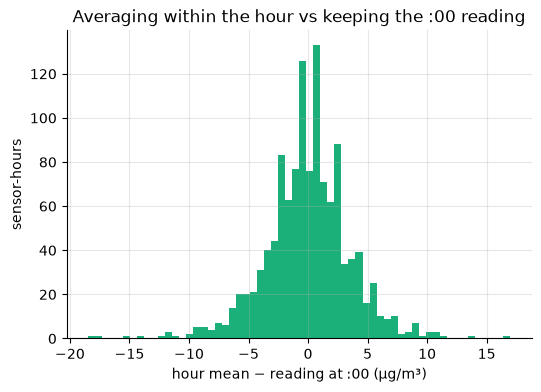

In [9]:
multi = hourly.loc[hourly.n_raw > 1, "sensor_id"].unique()
at00 = long_raw[(long_raw.minute == 0) & ~long_raw.raw_bad].set_index(["sensor_id", "hour"]).pm25
cmp = hourly[hourly.sensor_id.isin(multi) & ~hourly.all_bad].set_index(["sensor_id", "timestamp_utc"])["pm25"]
cmp = pd.concat([cmp.rename("hour_mean"), at00.rename("at_00").rename_axis(["sensor_id", "timestamp_utc"])], axis=1, join="inner")
d = cmp.hour_mean - cmp.at_00
print(f"sensor-hours compared: {len(d)} (sensors {list(multi)})")
print(f"hour mean − :00 reading: mean {d.mean():+.2f}, mean |diff| {d.abs().mean():.2f}, RMS {np.sqrt((d**2).mean()):.2f}, 95th pct |diff| {d.abs().quantile(.95):.2f} µg/m³")
print(f"relative to the level: median |diff| / level = {(d.abs() / cmp.hour_mean).median():.1%}")
hours_no00 = hourly[hourly.sensor_id.isin(multi)].shape[0] - len(cmp)
print(f"hours of these sensors that have readings but none at :00 (lost entirely by the ':00 only' rule): {hours_no00}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(d, bins=60, color="#1baf7a"); ax.set_xlabel("hour mean − reading at :00 (µg/m³)"); ax.set_ylabel("sensor-hours")
ax.set_title("Averaging within the hour vs keeping the :00 reading")
savefig(fig, "part0_mean_vs_00.png"); plt.show()

**Average vs :00.** Only one sensor (the hex one) reports more than once per hour, so for 75 of 76 sensors both methods give identical numbers. For the hex sensor the hourly mean differs from the :00 reading by **3.5 µg/m³ RMS** (mean |diff| 2.6, 95th percentile 7.3), about **8.5 % of the level** — comparable to the within-hour variability of the sensor. The mean is less noisy (it averages four samples), has almost no bias relative to :00 (−0.02), and also keeps the 4 hours in which the sensor reported but missed minute :00. Averaging is the better choice.

## 3. Detect problems and flag them

### 3b. Stuck values: the same value for ≥ 24 consecutive *reported* hours

We look at each sensor's sequence of reported hourly values (gaps are skipped — "consecutive reported hours"), find runs of an identical value, and examine the distribution of run lengths. Zeros are already flagged as `zero`; here we look at non-zero plausible values.

**Why 24 h is a sensible threshold:** a working sensor with integer resolution can repeat the same value for a few hours on a calm night, but PM2.5 has a daily cycle, so a full day without any change is very unlikely. The plot shows whether natural runs stay well below 24 and faulty runs sit far above it.

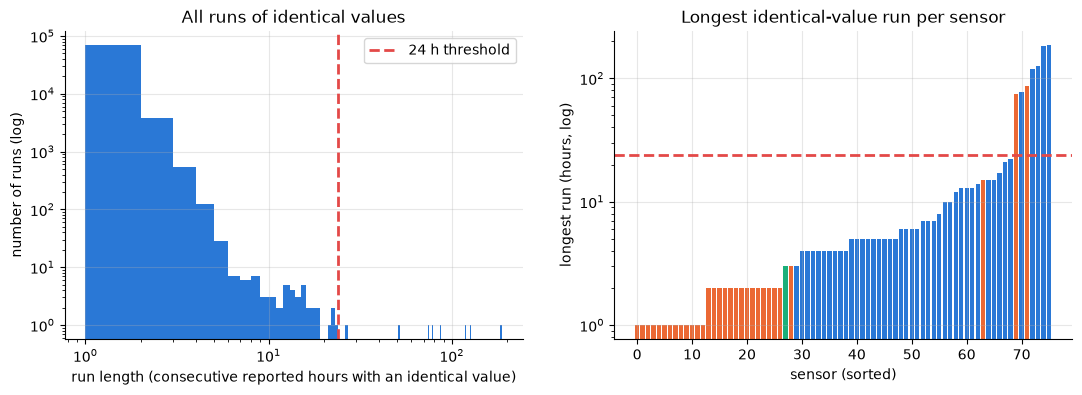

longest run among sensors WITHOUT a >=24 h run: 22 hours


,sensor_id,run_id,run_len,value,family
12994,1203260082,20,186,52.00,10-digit
7253,1203260068,1,184,65.00,10-digit
20215,1203260146,69,126,78.00,10-digit
30169,1204260005,10,118,21.00,10-digit
73554,ZQQZB912,278,86,59.61,8-char
13280,1203260084,105,78,31.00,10-digit
63956,RZGVBSNC,684,74,14.20,8-char
30168,1204260005,9,51,74.00,10-digit
63964,RZGVBSNC,692,26,60.87,8-char


In [10]:
hourly = hourly.sort_values(["sensor_id", "timestamp_utc"]).reset_index(drop=True)
cand = hourly[~hourly.all_bad].copy()
cand["run_id"] = (cand.groupby("sensor_id").pm25.transform(lambda s: (s != s.shift()).cumsum()))
cand["run_len"] = cand.groupby(["sensor_id", "run_id"]).pm25.transform("size")
runs = cand.groupby(["sensor_id", "run_id"]).agg(run_len=("run_len", "first"), value=("pm25", "first")).reset_index()
max_run = runs.groupby("sensor_id").run_len.max().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(runs.run_len, bins=np.arange(1, runs.run_len.max() + 2), color="#2a78d6"); axes[0].set_yscale("log"); axes[0].set_xscale("log")
axes[0].axvline(24, color="#e34948", ls="--", label="24 h threshold"); axes[0].legend()
axes[0].set_xlabel("run length (consecutive reported hours with an identical value)"); axes[0].set_ylabel("number of runs (log)")
axes[0].set_title("All runs of identical values")
axes[1].bar(range(len(max_run)), max_run.values, color=[FAM_COLORS[fam[i]] for i in max_run.index])
axes[1].axhline(24, color="#e34948", ls="--"); axes[1].set_yscale("log")
axes[1].set_xlabel("sensor (sorted)"); axes[1].set_ylabel("longest run (hours, log)"); axes[1].set_title("Longest identical-value run per sensor")
savefig(fig, "part0_stuck_runs.png"); plt.show()

STUCK_HOURS = 24
long_runs = runs[runs.run_len >= STUCK_HOURS]
print("longest run among sensors WITHOUT a >=24 h run:", int(max_run[max_run < STUCK_HOURS].max()), "hours")
display(long_runs.sort_values("run_len", ascending=False).assign(family=lambda d: d.sensor_id.map(fam)))
hourly["is_stuck"] = False
hourly.loc[cand.index[cand.run_len >= STUCK_HOURS], "is_stuck"] = True

**Why 24 h is justified.** The run-length histogram has a clear gap: among sensors without a long run, the **longest natural repeat is 22 hours** (integer-resolution sensors can repeat a value for many hours on calm nights), while the faulty runs are **74–186 hours** long. The 24 h threshold falls inside this gap, so it neither flags normal behaviour nor misses a fault.
**Caught:** 929 hourly readings in 7 sensors (5 × 10-digit, 2 × 8-char). Two of them (`1203260082`, `1203260068`) are the same sensors that also emit long zero runs. For 8-char sensors, reporting an identical *4-decimal* value for 74–86 hours is impossible for a working instrument.

### 3c. Mostly unusable sensors (> 50 % of readings flagged)

For each sensor: share of its reported hours flagged by any reading-level check (error code, out of range, zero, stuck). Above 50 % (PDF threshold) the sensor is marked `dropped_sensor`: its remaining "ok" hours are surrounded by faults and cannot be trusted either. The plot shows how clearly the threshold separates sensors.

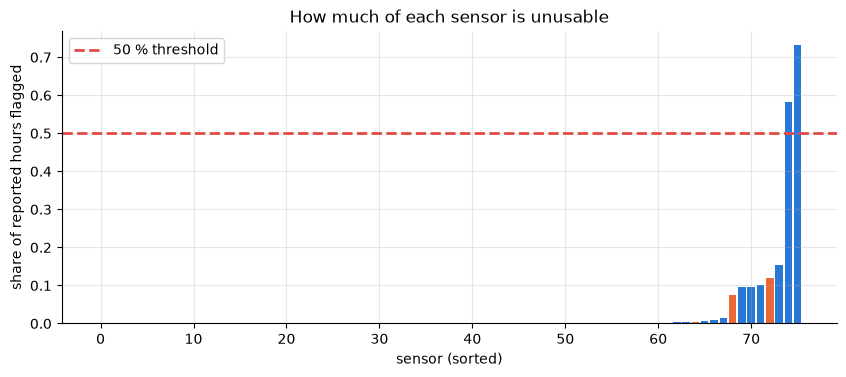

sensors above 50 %: {'1203260068': np.float64(0.584), '1203260082': np.float64(0.733)}
next highest share: {'1204260025': 0.102, 'RZGVBSNC': 0.119, '1204260005': 0.154}


In [11]:
hourly["is_error_code"] = hourly.all_bad & hourly.any_error_code
hourly["is_out_of_range"] = hourly.all_bad & hourly.any_out_of_range & ~hourly.is_error_code
hourly["is_zero"] = hourly.all_bad & hourly.any_zero & ~hourly.is_error_code & ~hourly.is_out_of_range
hourly["reading_flagged"] = hourly[["is_error_code", "is_out_of_range", "is_zero", "is_stuck"]].any(axis=1)
share_flagged = hourly.groupby("sensor_id").reading_flagged.mean().sort_values()
DROP_SHARE = 0.5
dropped = share_flagged[share_flagged > DROP_SHARE].index.tolist()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(share_flagged)), share_flagged.values, color=[FAM_COLORS[fam[i]] for i in share_flagged.index])
ax.axhline(DROP_SHARE, color="#e34948", ls="--", label="50 % threshold"); ax.legend()
ax.set_xlabel("sensor (sorted)"); ax.set_ylabel("share of reported hours flagged"); ax.set_title("How much of each sensor is unusable")
savefig(fig, "part0_share_flagged.png"); plt.show()
print("sensors above 50 %:", {s: round(share_flagged[s], 3) for s in dropped})
print("next highest share:", share_flagged[share_flagged <= DROP_SHARE].tail(3).round(3).to_dict())
hourly["in_dropped_sensor"] = hourly.sensor_id.isin(dropped)

**Two sensors are mostly unusable:** `1203260082` (73 % of its hours flagged) and `1203260068` (58 %). Their remaining "normal-looking" hours are islands between long zero and stuck runs, so we mark them `dropped_sensor` (600 otherwise-ok hours). The threshold separates them cleanly: the next-worst sensors have only 10–15 % of hours flagged, far below 50 %.

### 3d. Network outages (hours when fewer than 10 % of sensors report)

10 % of 76 sensors = 7.6, so an outage hour has at most 7 reporting sensors. We count reporting sensors per hour on the full hourly time grid (hours with nobody reporting do not appear in the long table, so we must use the full grid to see them).

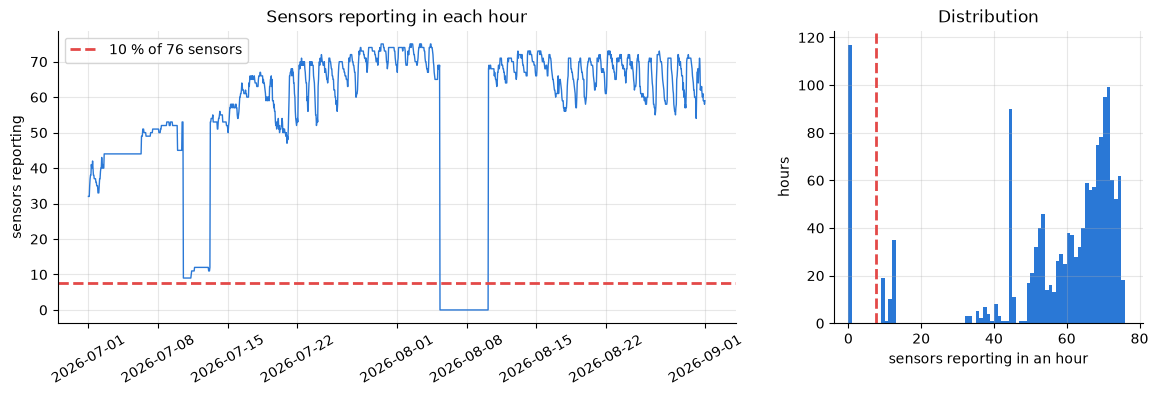

outage hours: 117 in 1 block(s): [('2026-08-05 08:00:00+00:00', '2026-08-10 04:00:00+00:00', 117)]
readings inside outage hours: 0
'partial' hours with 8-18 sensors (above the 10 % line): 65; families reporting in them: {'8-char': 646, '12-char hex': 65}


In [12]:
full_hours = pd.date_range(raw.index.min().floor("h"), raw.index.max().floor("h"), freq="h")
n_report = hourly.groupby("timestamp_utc").sensor_id.nunique().reindex(full_hours, fill_value=0)
OUTAGE_FRAC = 0.10
outage_hours = n_report.index[n_report < OUTAGE_FRAC * len(ids)]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(n_report.index, n_report.values, color="#2a78d6", lw=1)
axes[0].axhline(OUTAGE_FRAC * len(ids), color="#e34948", ls="--", label="10 % of 76 sensors")
axes[0].set_ylabel("sensors reporting"); axes[0].set_title("Sensors reporting in each hour"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(n_report.values, bins=np.arange(0, 78), color="#2a78d6"); axes[1].axvline(OUTAGE_FRAC * len(ids), color="#e34948", ls="--")
axes[1].set_xlabel("sensors reporting in an hour"); axes[1].set_ylabel("hours"); axes[1].set_title("Distribution")
savefig(fig, "part0_outages.png"); plt.show()

blocks = pd.Series(outage_hours).diff().ne(pd.Timedelta("1h")).cumsum()
print(f"outage hours: {len(outage_hours)} in {blocks.nunique()} block(s):",
      [(str(b.min()), str(b.max()), len(b)) for _, b in pd.Series(outage_hours).groupby(blocks.values)])
print("readings inside outage hours:", int(hourly.timestamp_utc.isin(outage_hours).sum()))
partial = n_report[(n_report >= OUTAGE_FRAC * len(ids)) & (n_report < 0.25 * len(ids))]
part_fams = hourly[hourly.timestamp_utc.isin(partial.index)].sensor_id.map(fam).value_counts().to_dict()
print(f"'partial' hours with 8-18 sensors (above the 10 % line): {len(partial)}; families reporting in them: {part_fams}")
hourly["in_outage_hour"] = hourly.timestamp_utc.isin(outage_hours)

**Network outage:** 117 consecutive hours, 5 Aug 08:00 → 10 Aug 04:00 UTC, with **no sensor reporting at all** — a central failure (server / power / connectivity), not individual sensors. The 10 % threshold catches exactly this block. There are no readings inside these hours to flag, so in the clean file every sensor gets `outage` (not `missing`) for these hours, which tells a user the gap is network-wide.
The distribution also shows **65 "partial" hours** with only 9–12 reporters: in those, *only* 8-char sensors (and the hex sensor) report — the whole 10-digit family is offline. They are above the 10 % threshold so they are not outages, but a network average computed in those hours represents only one device family; we report this rather than flag it.

### 3e. Sensors that barely follow the rest of the network

PM2.5 over a city is driven largely by the same weather (mixing height, rain, wind), so a working sensor should rise and fall with the network. For each sensor we compute the correlation between its usable hourly values and the **median of all other sensors** in the same hours (leave-one-out, so a sensor is not compared with itself). We use only readings that passed the checks above, so a broken sensor's error codes do not drive the result.

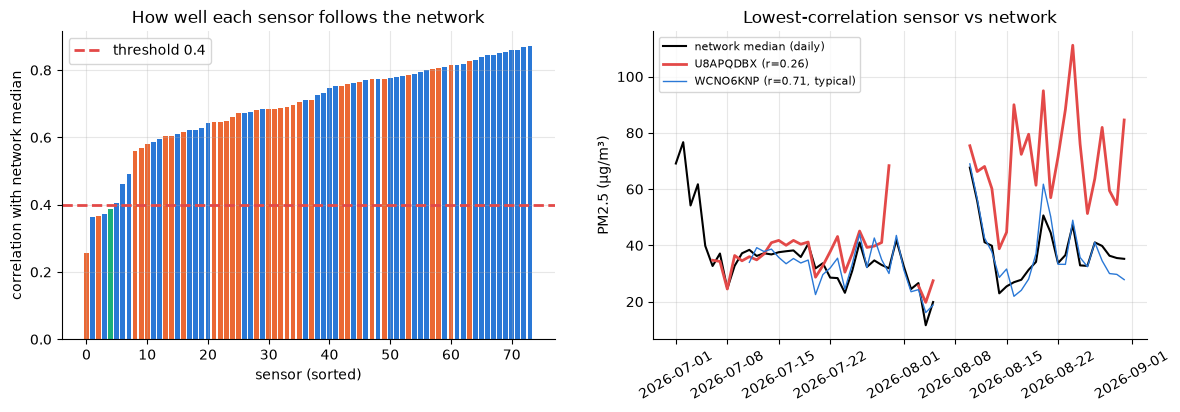

,corr_with_network,n_hours,family
U8APQDBX,0.256,1128.0,8-char
1203260075,0.362,1064.0,10-digit
TUOBZVJ0,0.365,1229.0,8-char
1204260025,0.373,1170.0,10-digit
AC0BFBE34CC7,0.388,1210.0,12-char hex
1203260084,0.406,751.0,10-digit
1203260125,0.461,987.0,10-digit
1204260010,0.490,1111.0,10-digit
DDJMYBH3,0.558,1005.0,8-char
UI2WKRUR,0.570,798.0,8-char


median correlation 0.71; sensors below 0.4: ['U8APQDBX', '1203260075', 'TUOBZVJ0', '1204260025', 'AC0BFBE34CC7']


In [13]:
usable = hourly[~hourly.reading_flagged & ~hourly.in_dropped_sensor]
Wide = usable.pivot(index="timestamp_utc", columns="sensor_id", values="pm25")
corr = {}
for s in Wide.columns:
    others = Wide.drop(columns=s).median(axis=1)
    ok = Wide[s].notna() & others.notna()
    corr[s] = (Wide.loc[ok, s].corr(others[ok]), int(ok.sum()))
corr = pd.DataFrame(corr, index=["corr_with_network", "n_hours"]).T.sort_values("corr_with_network")
corr["family"] = corr.index.map(fam)

LOWCORR = 0.4
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(len(corr)), corr.corr_with_network, color=[FAM_COLORS[f] for f in corr.family])
axes[0].axhline(LOWCORR, color="#e34948", ls="--", label=f"threshold {LOWCORR}"); axes[0].legend()
axes[0].set_xlabel("sensor (sorted)"); axes[0].set_ylabel("correlation with network median"); axes[0].set_title("How well each sensor follows the network")
worst, typical = corr.index[0], corr.index[len(corr) // 2]
net = Wide.median(axis=1).resample("D").mean()
axes[1].plot(net.index, net, color="black", lw=1.5, label="network median (daily)")
axes[1].plot(net.index, Wide[worst].resample("D").mean(), color="#e34948", label=f"{worst} (r={corr.loc[worst, 'corr_with_network']:.2f})")
axes[1].plot(net.index, Wide[typical].resample("D").mean(), color="#2a78d6", lw=1, label=f"{typical} (r={corr.loc[typical, 'corr_with_network']:.2f}, typical)")
axes[1].set_ylabel("PM2.5 (µg/m³)"); axes[1].set_title("Lowest-correlation sensor vs network"); axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=30)
savefig(fig, "part0_low_correlation.png"); plt.show()

low_corr = corr.index[corr.corr_with_network < LOWCORR].tolist()
display(corr.head(10).round(3))
print(f"median correlation {corr.corr_with_network.median():.2f}; sensors below {LOWCORR}: {low_corr}")
hourly["in_low_corr_sensor"] = hourly.sensor_id.isin(low_corr)

**Sensors that barely follow the network.** The median sensor correlates **0.71** with the leave-one-out network median. We flag sensors with **r < 0.4**, i.e. less than 16 % of their hourly variance shared with the network (r² < 0.16). There is no sharp gap in the distribution, so this is a judgement call: 0.4 sits well below the bulk (interquartile range ≈ 0.6–0.8) and catches the five sensors whose daily curves visibly fail to track the network; the next sensors (0.41–0.49) are borderline and stay `ok`. Flagged: `U8APQDBX` (0.26), `1203260075`, `TUOBZVJ0`, `1204260025`, and the hex sensor `AC0BFBE34CC7` (0.39). Their readings may be real but very local (a nearby source) or the result of a degrading sensor (`1204260025` also produces the error codes). We do **not** delete them: their otherwise-ok hours get the soft flag `low_corr`, usable with caution.

## 4. Write `kanpur_hourly_clean.csv`

**Layout:** the full grid of 76 sensors × 1,488 hours, so that gaps are visible as rows with `pm25` = NaN (we never fill them).

**One `flag` per row**, by priority (the most specific, reading-level reason wins):

| flag | meaning |
|---|---|
| `error_code` | every raw reading in the hour was the code 999 |
| `out_of_range` | every raw reading was > 500 µg/m³ |
| `zero` | every raw reading was exactly 0 |
| `stuck` | part of a run of ≥ 24 identical reported hourly values |
| `dropped_sensor` | otherwise fine, but the sensor has > 50 % of its hours flagged |
| `low_corr` | otherwise fine, but the sensor barely follows the network (r < 0.4) — usable with caution |
| `ok` | passed every check |
| `outage` | no reading, and the hour is a network outage (< 10 % of sensors reporting) |
| `missing` | no reading (sensor-level gap) |

We also keep one boolean column per check, so a reading caught by two checks loses no information, and `n_raw` (raw readings averaged in the hour). For flagged rows `pm25` keeps the (averaged) raw value — e.g. 999 — so nothing is deleted.

In [14]:
grid_rows = pd.MultiIndex.from_product([ids, full_hours], names=["sensor_id", "timestamp_utc"])
clean = hourly.set_index(["sensor_id", "timestamp_utc"]).reindex(grid_rows).reset_index()
clean["latitude"] = clean.sensor_id.map(lat.median()).round(6)
clean["longitude"] = clean.sensor_id.map(lon.median()).round(6)
bool_cols = ["is_error_code", "is_out_of_range", "is_zero", "is_stuck", "in_dropped_sensor", "in_low_corr_sensor", "in_outage_hour"]
clean["in_dropped_sensor"] = clean.sensor_id.isin(dropped)
clean["in_low_corr_sensor"] = clean.sensor_id.isin(low_corr)
clean["in_outage_hour"] = clean.timestamp_utc.isin(outage_hours)
for c in bool_cols:
    clean[c] = clean[c].astype("boolean").fillna(False).astype(bool)
clean["n_raw"] = clean["n_raw"].fillna(0).astype(int)

has_value = clean.pm25.notna()
conditions = [
    has_value & clean.is_error_code, has_value & clean.is_out_of_range, has_value & clean.is_zero, has_value & clean.is_stuck,
    has_value & clean.in_dropped_sensor, has_value & clean.in_low_corr_sensor, has_value,
    ~has_value & clean.in_outage_hour, ~has_value,
]
choices = ["error_code", "out_of_range", "zero", "stuck", "dropped_sensor", "low_corr", "ok", "outage", "missing"]
clean["flag"] = np.select(conditions, choices, default="missing")

out = clean[["sensor_id", "timestamp_utc", "latitude", "longitude", "pm25", "flag", "n_raw"] + bool_cols].copy()
out["timestamp_utc"] = out.timestamp_utc.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
out["pm25"] = out.pm25.round(3)
out.to_csv(MP1 / "kanpur_hourly_clean.csv", index=False)

assert len(out) == len(ids) * len(full_hours)
assert out.loc[out.flag.isin(["missing", "outage"]), "pm25"].isna().all()       # gaps are NOT filled
assert out.loc[~out.flag.isin(["missing", "outage"]), "pm25"].notna().all()
assert int((out.pm25.notna()).sum()) == len(hourly)                               # every hourly reading kept
print("wrote kanpur_hourly_clean.csv:", out.shape)
flag_table = out.groupby("flag").agg(rows=("pm25", "size"), sensors=("sensor_id", "nunique")).reindex(choices)
display(flag_table)
display(out[out.flag != "missing"].head())

wrote kanpur_hourly_clean.csv: (113088, 14)


,rows,sensors
flag,,
error_code,136,5
out_of_range,28,11
zero,813,21
stuck,929,7
dropped_sensor,600,2
low_corr,5801,5
ok,73824,69
outage,8892,76
missing,22065,76


,sensor_id,timestamp_utc,latitude,longitude,pm25,flag,n_raw,is_error_code,is_out_of_range,is_zero,is_stuck,in_dropped_sensor,in_low_corr_sensor,in_outage_hour
393,01DQW5QE,2026-07-17T09:00:00Z,26.12636,80.187592,28.974,ok,1,False,False,False,False,False,False,False
394,01DQW5QE,2026-07-17T10:00:00Z,26.12636,80.187592,32.374,ok,1,False,False,False,False,False,False,False
395,01DQW5QE,2026-07-17T11:00:00Z,26.12636,80.187592,35.883,ok,1,False,False,False,False,False,False,False
396,01DQW5QE,2026-07-17T12:00:00Z,26.12636,80.187592,28.117,ok,1,False,False,False,False,False,False,False
397,01DQW5QE,2026-07-17T13:00:00Z,26.12636,80.187592,27.997,ok,1,False,False,False,False,False,False,False


### Summary of every check

In [15]:
summary = []
def add(check, threshold, mask):
    s = out.loc[mask, "sensor_id"]
    summary.append({"check": check, "threshold": threshold, "hourly readings caught": int(mask.sum()),
                    "sensors": s.nunique(), "which sensors": ", ".join(s.value_counts().index[:8]) + (" ..." if s.nunique() > 8 else "")})
add("error code", "value == 999", out.is_error_code)
add("out of range", "> 500 µg/m³", out.is_out_of_range)
add("implausible zero", "== 0", out.is_zero)
add("stuck", f"≥ {STUCK_HOURS} identical reported hours", out.is_stuck)
add("mostly unusable sensor", "> 50 % of hours flagged", out.in_dropped_sensor & out.pm25.notna())
add("barely follows network", f"r < {LOWCORR} with network median", out.in_low_corr_sensor & out.pm25.notna())
add("network outage (hours)", "< 10 % of sensors report", pd.Series(False, index=out.index))
summary = pd.DataFrame(summary)
summary.loc[summary.check == "network outage (hours)", ["hourly readings caught", "which sensors"]] = [0, f"{len(outage_hours)} hours with no data at all"]
display(summary)

,check,threshold,hourly readings caught,sensors,which sensors
0,error code,value == 999,136,5,"1204260025, 1203260086, 1203260075, 1203260125..."
1,out of range,> 500 µg/m³,28,11,"1204260025, 1203260075, 1204260032, 1204260039..."
2,implausible zero,== 0,813,21,"1203260082, 1203260068, 1204260039, 1204260005..."
3,stuck,≥ 24 identical reported hours,929,7,"1203260082, 1203260068, 1204260005, 1203260146..."
4,mostly unusable sensor,> 50 % of hours flagged,1734,2,"1203260068, 1203260082"
5,barely follows network,r < 0.4 with network median,5946,5,"1204260025, TUOBZVJ0, AC0BFBE34CC7, U8APQDBX, ..."
6,network outage (hours),< 10 % of sensors report,0,0,117 hours with no data at all


## 5. Calibration check between the two device families

The two main ID styles may be different device types with different calibrations. We:
1. pair each **10-digit** sensor with its **nearest 8-char** sensor if it is **within 3 km** (km coordinates with the PDF's formula; the hex sensor belongs to neither family and is left out);
2. use only hours where **both** sensors of a pair have an `ok` reading;
3. **fit** a linear correction 8-char ≈ a + b · (10-digit) on **July** hours (pooled over all pairs — one correction for the device type);
4. **test** on **August**: does the disagreement between pair members (RMSE, MAE, mean difference) drop after correcting the 10-digit readings?

This is a train/test split in time, the same idea as in Parts 1–5: a correction is only useful if it holds on data it was not fitted on.

In [16]:
xy_k = D.to_km(lon.median().values, lat.median().values)
Dk = D.distance_matrix_km(xy_k)
idx = {s: k for k, s in enumerate(ids)}
ten = [s for s in ids if fam[s] == "10-digit"]; eight = [s for s in ids if fam[s] == "8-char"]
pairs = []
for s in ten:
    d = Dk[idx[s], [idx[e] for e in eight]]
    j = int(np.argmin(d))
    if d[j] <= 3.0:
        pairs.append((s, eight[j], round(float(d[j]), 2)))
pairs = pd.DataFrame(pairs, columns=["sensor_10digit", "sensor_8char", "distance_km"])
print(f"{len(pairs)} of {len(ten)} 10-digit sensors have an 8-char sensor within 3 km "
      f"({pairs.sensor_8char.nunique()} distinct 8-char partners)")

okW = out[out.flag == "ok"].assign(t=lambda d: pd.to_datetime(d.timestamp_utc)).pivot(index="t", columns="sensor_id", values="pm25")
rows = []
for _, p in pairs.iterrows():
    if p.sensor_10digit in okW and p.sensor_8char in okW:
        both = okW[[p.sensor_10digit, p.sensor_8char]].dropna()
        rows.append(pd.DataFrame({"pair": p.sensor_10digit + "~" + p.sensor_8char, "t": both.index,
                                  "x10": both[p.sensor_10digit].values, "y8": both[p.sensor_8char].values}))
pairdata = pd.concat(rows, ignore_index=True)
pairdata["month"] = pairdata.t.dt.month
jul, aug = pairdata[pairdata.month == 7], pairdata[pairdata.month == 8]
print(f"paired ok hours: July {len(jul)} ({jul.pair.nunique()} pairs), August {len(aug)} ({aug.pair.nunique()} pairs)")
display(pairs.head(10))

23 of 44 10-digit sensors have an 8-char sensor within 3 km (13 distinct 8-char partners)


paired ok hours: July 7398 (20 pairs), August 10723 (20 pairs)


,sensor_10digit,sensor_8char,distance_km
0,1203260063,BEQBDBTZ,2.71
1,1203260066,BPVCUQ5W,2.80
2,1203260067,DNYU7SEW,1.10
3,1203260068,7HZBUU8B,2.38
4,1203260075,BEQBDBTZ,2.41
5,1203260078,CTU30PGT,2.42
6,1203260081,DDJMYBH3,2.23
7,1203260082,C7X23C3J,2.53
8,1203260086,OROLHDYZ,2.48
9,1203260128,04TGTKIS,2.48


July fit: 8-char ≈ 22.88 + 0.396 × 10-digit


,RMSE,MAE,mean diff (10d − 8c),corr
"July, raw (fit data)",18.640,10.944,-1.379,0.333
"July, corrected (in-sample)",16.364,10.679,-0.000,0.333
"August, raw",20.525,11.921,-1.796,0.573
"August, corrected (test)",21.533,13.799,-1.024,0.573
"August, offset-only correction (test)",20.451,12.066,-0.417,0.573


pairs improved in August: 4 of 20


,n,RMSE raw,RMSE corrected,mean diff raw,improved
pair,,,,,
1203260063~BEQBDBTZ,626.0,26.37,26.72,-10.59,False
1203260066~BPVCUQ5W,621.0,25.05,27.20,-9.46,False
1203260067~DNYU7SEW,607.0,21.50,24.25,-15.05,False
1203260078~CTU30PGT,613.0,9.97,12.04,-1.54,False
1203260081~DDJMYBH3,625.0,21.68,24.22,0.47,False
1203260086~OROLHDYZ,622.0,11.56,15.50,1.03,False
1203260128~04TGTKIS,477.0,16.22,16.60,10.62,False
1203260143~7HZBUU8B,89.0,9.35,13.65,3.22,False
1203260144~UGYZAWR7,390.0,12.63,14.70,6.08,False


per-pair corrections (pairs with >= 48 July and August hours: 20): mean Aug RMSE raw 18.68 -> corrected 17.99


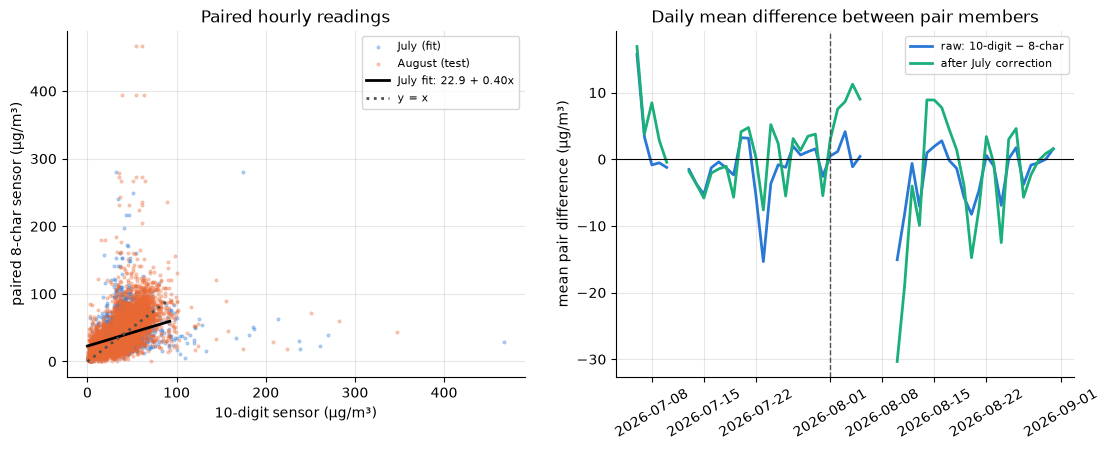

In [17]:
# fit on July (ordinary least squares, Lecture 5 closed form via np.polyfit)
b, a = np.polyfit(jul.x10, jul.y8, deg=1)
print(f"July fit: 8-char ≈ {a:.2f} + {b:.3f} × 10-digit")

def disagreement(x, y):
    d = x - y
    return {"RMSE": np.sqrt(np.mean(d ** 2)), "MAE": np.mean(np.abs(d)), "mean diff (10d − 8c)": np.mean(d), "corr": np.corrcoef(x, y)[0, 1]}

calib = pd.DataFrame({
    "July, raw (fit data)": disagreement(jul.x10, jul.y8),
    "July, corrected (in-sample)": disagreement(a + b * jul.x10, jul.y8),
    "August, raw": disagreement(aug.x10, aug.y8),
    "August, corrected (test)": disagreement(a + b * aug.x10, aug.y8),
    "August, offset-only correction (test)": disagreement(aug.x10 - (jul.x10 - jul.y8).mean(), aug.y8),
}).T
display(calib.round(3))

# per-pair view in August: does the pooled correction help each pair?
per_pair = aug.groupby("pair").apply(lambda g: pd.Series({
    "n": len(g), "RMSE raw": np.sqrt(np.mean((g.x10 - g.y8) ** 2)), "RMSE corrected": np.sqrt(np.mean((a + b * g.x10 - g.y8) ** 2)),
    "mean diff raw": np.mean(g.x10 - g.y8)}), include_groups=False)
per_pair["improved"] = per_pair["RMSE corrected"] < per_pair["RMSE raw"]
print(f"pairs improved in August: {int(per_pair.improved.sum())} of {len(per_pair)}")
display(per_pair.round(2))

# a per-pair correction (fit each pair on its own July data) as a comparison
pp_rows = []
for pr, g in pairdata.groupby("pair"):
    gj, ga = g[g.month == 7], g[g.month == 8]
    if len(gj) >= 48 and len(ga) >= 48:
        bb, aa = np.polyfit(gj.x10, gj.y8, 1)
        pp_rows.append((pr, np.sqrt(np.mean((ga.x10 - ga.y8) ** 2)), np.sqrt(np.mean((aa + bb * ga.x10 - ga.y8) ** 2))))
pp = pd.DataFrame(pp_rows, columns=["pair", "Aug RMSE raw", "Aug RMSE per-pair corrected"])
print(f"per-pair corrections (pairs with >= 48 July and August hours: {len(pp)}): mean Aug RMSE raw {pp['Aug RMSE raw'].mean():.2f} -> corrected {pp['Aug RMSE per-pair corrected'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(jul.x10, jul.y8, s=4, alpha=0.3, color="#2a78d6", label="July (fit)")
axes[0].scatter(aug.x10, aug.y8, s=4, alpha=0.3, color="#eb6834", label="August (test)")
xx = np.linspace(0, np.percentile(pairdata.x10, 99.5), 50)
axes[0].plot(xx, a + b * xx, color="black", label=f"July fit: {a:.1f} + {b:.2f}x"); axes[0].plot(xx, xx, color="#52514e", ls=":", label="y = x")
axes[0].set_xlabel("10-digit sensor (µg/m³)"); axes[0].set_ylabel("paired 8-char sensor (µg/m³)"); axes[0].set_title("Paired hourly readings"); axes[0].legend(fontsize=8)
daily_bias = pairdata.assign(d=pairdata.x10 - pairdata.y8).set_index("t").d.resample("D").mean()
axes[1].plot(daily_bias.index, daily_bias.values, color="#2a78d6", label="raw: 10-digit − 8-char")
daily_bias_c = pairdata.assign(d=a + b * pairdata.x10 - pairdata.y8).set_index("t").d.resample("D").mean()
axes[1].plot(daily_bias_c.index, daily_bias_c.values, color="#1baf7a", label="after July correction")
axes[1].axhline(0, color="black", lw=0.8); axes[1].axvline(pd.Timestamp("2026-08-01", tz="UTC"), color="#52514e", ls="--", lw=1)
axes[1].set_ylabel("mean pair difference (µg/m³)"); axes[1].set_title("Daily mean difference between pair members"); axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=30)
savefig(fig, "part0_calibration.png"); plt.show()

**Result: the July correction does *not* reduce August disagreement — it makes it worse.**
* 20 pairs (23 of 44 10-digit sensors have an 8-char sensor within 3 km). July fit: 8-char ≈ 22.9 + 0.40 × 10-digit.
* In-sample (July) the pooled RMSE drops 18.6 → 16.4 µg/m³, but on the **August test** it rises 20.5 → 21.5 (MAE 11.9 → 13.8), and only 4 of 20 pairs improve.

**Why.**
1. **There is hardly any systematic family offset to correct.** The mean difference between pair members is only −1.4 (Jul) / −1.8 µg/m³ (Aug), and the families' hour-by-hour medians differ by ≈ 2 µg/m³ (ratio 1.03). An offset-only correction (subtract the July mean difference) confirms this: August RMSE moves only from 20.53 to 20.45, and MAE gets slightly worse (11.92 → 12.07).
2. **Pair members agree poorly hour by hour** (correlation 0.33 in July, 0.57 in August). With noisy *x*, least squares **shrinks the slope towards 0** (here 0.40 instead of ≈ 1; "regression dilution"), so the "correction" mostly pulls 10-digit readings toward the 8-char July mean. That reduces squared error on July but compresses real variation, which hurts in August, when pollution levels and the pair correlation are different.
3. **The disagreement is pair-specific, not device-type-specific.** Mean pair differences range from −18 to +11 µg/m³ with both signs inside the same family; up to 3 km apart, sensors sit in different micro-environments (roads, cooking, construction). Per-pair corrections help only slightly (mean August RMSE 18.7 → 18.0) because local, time-varying differences dominate.

**Conclusion:** the two families are already on nearly the same scale; a family-level calibration is not supported by this data. A real calibration would need **co-located** sensors (same site) or a reference monitor.

## 6. Summary: before / after, and the network's daily cycle in local time

**Before** = the raw 15-minute file; **hourly** = after reshaping (still including flagged values); **after** = only rows flagged `ok` (what an analyst would use; `low_corr` rows are counted separately because they are usable with caution).

In [18]:
n_slots = pm.size
n_grid = len(ids) * len(full_hours)
ok_rows = out[out.flag == "ok"]
lc_rows = out[out.flag == "low_corr"]
before_after = pd.DataFrame([
    {"stage": "raw file (15-min grid)", "sensors with data": int(pm.notna().any().sum()), "readings": int(pm.notna().sum().sum()),
     "possible readings": n_slots, "share missing": 1 - pm.notna().sum().sum() / n_slots},
    {"stage": "hourly long table (all values)", "sensors with data": hourly.sensor_id.nunique(), "readings": len(hourly),
     "possible readings": n_grid, "share missing": 1 - len(hourly) / n_grid},
    {"stage": "after cleaning: flag == ok", "sensors with data": ok_rows.sensor_id.nunique(), "readings": len(ok_rows),
     "possible readings": n_grid, "share missing": 1 - len(ok_rows) / n_grid},
    {"stage": "after cleaning: ok + low_corr", "sensors with data": pd.concat([ok_rows, lc_rows]).sensor_id.nunique(),
     "readings": len(ok_rows) + len(lc_rows), "possible readings": n_grid, "share missing": 1 - (len(ok_rows) + len(lc_rows)) / n_grid},
]).set_index("stage")
before_after["share missing"] = before_after["share missing"].round(3)
display(before_after)

,sensors with data,readings,possible readings,share missing
stage,,,,
raw file (15-min grid),76,85762,452352,0.810
hourly long table (all values),76,82131,113088,0.274
after cleaning: flag == ok,69,73824,113088,0.347
after cleaning: ok + low_corr,74,79625,113088,0.296


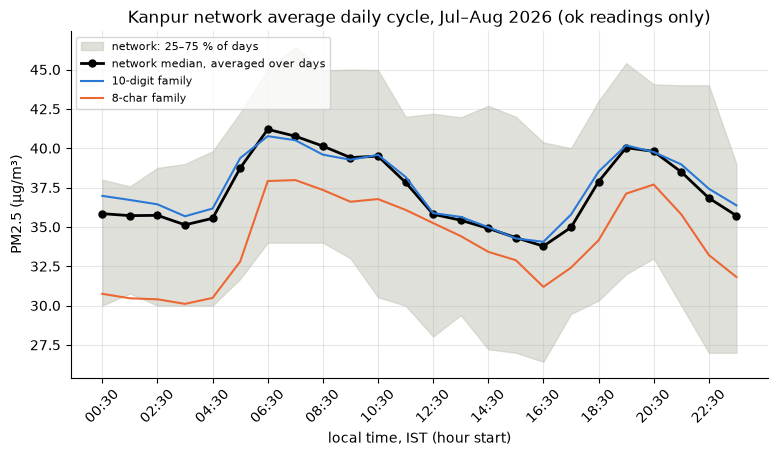

peak at 06:30 IST (41.2 µg/m³), minimum at 16:30 IST (33.8 µg/m³)


In [19]:
okt = ok_rows.assign(t=pd.to_datetime(ok_rows.timestamp_utc))
okt["ist"] = okt.t.dt.tz_convert("Asia/Kolkata")                         # IST = UTC + 5:30
okt["ist_hour"] = okt.ist.dt.hour + okt.ist.dt.minute / 60               # hour starts land on hh:30 in IST
okt["family"] = okt.sensor_id.map(fam)
# network value per hour = median over sensors (robust), then average over days
net_hour = okt.groupby(["t", "ist_hour"]).pm25.median().reset_index()
cycle = net_hour.groupby("ist_hour").pm25.agg(["mean", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
cycle.columns = ["mean", "q25", "q75"]
fam_cycle = okt.groupby(["family", "t", "ist_hour"]).pm25.median().groupby(["family", "ist_hour"]).mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(cycle.index, cycle.q25, cycle.q75, color="#c3c2b7", alpha=0.5, label="network: 25–75 % of days")
ax.plot(cycle.index, cycle["mean"], "o-", color="black", markersize=5, label="network median, averaged over days")
for f in ["10-digit", "8-char"]:
    ax.plot(fam_cycle.index, fam_cycle[f], color=FAM_COLORS[f], lw=1.5, label=f"{f} family")
ax.set_xticks(np.arange(0.5, 24, 2)); ax.set_xticklabels([f"{int(h):02d}:30" for h in np.arange(0.5, 24, 2)], rotation=45)
ax.set_xlabel("local time, IST (hour start)"); ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Kanpur network average daily cycle, Jul–Aug 2026 (ok readings only)"); ax.legend(fontsize=8)
savefig(fig, "part0_daily_cycle_ist.png"); plt.show()
fmt = lambda h: f"{int(h):02d}:{int(round((h % 1) * 60)):02d}"
print(f"peak at {fmt(cycle['mean'].idxmax())} IST ({cycle['mean'].max():.1f} µg/m³), minimum at {fmt(cycle['mean'].idxmin())} IST ({cycle['mean'].min():.1f} µg/m³)")

**Before / after.** The raw file has 85,762 readings in 452,352 fifteen-minute slots (81 % empty, mostly because sensors report hourly). After hourly reshaping there are 82,131 sensor-hours out of 113,088 possible (27.4 % missing). After cleaning, **73,824 hourly readings in 69 sensors are `ok`** (34.7 % of the grid missing or flagged); adding the cautious `low_corr` readings gives 79,625 readings in 74 sensors. Nothing was deleted or filled: every hourly value is still in the file with its flag.

**Daily cycle (IST).** Network PM2.5 is highest in the **early morning (peak ≈ 06:30 IST, ≈ 41 µg/m³)** and lowest in the **late afternoon (≈ 16:30 IST, ≈ 34 µg/m³)**. This is the classic boundary-layer cycle: at night the air near the ground is stable and shallow, trapping pollution; after sunrise heating deepens the mixed layer and dilutes it, until the evening when it collapses again. In the monsoon (Jul–Aug) the amplitude is modest (~20 %); the Bihar data in Part 3 shows the same shape, much stronger in winter. The two device families follow the same cycle, confirming they measure similar air.